# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Ngali Busthomi
- **Email:** ngali.busthomi@gmail.com
- **ID Dicoding:** ngalibusthomi

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pola rata-rata penyewaan sepeda per jam pada hari kerja dan hari nonkerja selama 2011–2012, serta periode waktu mana yang perlu diprioritaskan dalam penyediaan sepeda untuk mengantisipasi permintaan tertinggi?
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda pada empat kategori kondisi cuaca selama 2011–2012, dan bagaimana hasilnya dapat digunakan untuk menyesuaikan perencanaan operasional layanan?

## Import Semua Packages/Library yang Digunakan

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

**Load tabel hour**

In [2]:
hour_df = pd.read_csv("Bike-sharing-dataset/hour.csv")

hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Load tabel day**

In [3]:
day_df = pd.read_csv("Bike-sharing-dataset/day.csv")

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataset hour.csv berisi data penyewaan sepeda berdasarkan jam.
- Dataset day.csv berisi data penyewaan sepeda berdasarkan hari.
- Kedua dataset menyediakan informasi jumlah penyewaan sepeda yang dapat digunakan sebagai dasar analisis.

### Assessing Data

#### Identifying Data problem

**Menilai Data hour_df**

Memeriksa informasi umum dataset

In [4]:
# Memeriksa informasi umum dataset
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


Memeriksa missing value

In [5]:
# Memeriksa missing value
hour_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Memeriksa data duplikat

In [6]:
# Memeriksa data duplikat
print("Jumlah duplikasi: ", hour_df.duplicated().sum())

Jumlah duplikasi:  0


Memeriksa parameter statistik

In [7]:
# Memeriksa parameter statistik
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Memeriksaan nilai tidak valid

In [8]:
# Memeriksa rentang nilai pada kolom numerik
print("Jumlah jam di luar rentang 0-23:")
print((~hour_df["hr"].between(0, 23)).sum())

print("\nJumlah penyewaan negatif:")
print((hour_df["cnt"] < 0).sum())

print("\nJumlah casual negatif:")
print((hour_df["casual"] < 0).sum())

print("\nJumlah registered negatif:")
print((hour_df["registered"] < 0).sum())

print("\nJumlah temperature di luar rentang 0-1:")
print((~hour_df["temp"].between(0, 1)).sum())

print("\nJumlah humidity di luar rentang 0-1:")
print((~hour_df["hum"].between(0, 1)).sum())

print("\nJumlah windspeed di luar rentang 0-1:")
print((~hour_df["windspeed"].between(0, 1)).sum())

# Memeriksa nilai kategori yang tidak sesuai
valid_categories = {
    "season": [1, 2, 3, 4],
    "yr": [0, 1],
    "mnth": list(range(1, 13)),
    "holiday": [0, 1],
    "weekday": list(range(0, 7)),
    "workingday": [0, 1],
    "weathersit": [1, 2, 3, 4]
}
for column, valid_values in valid_categories.items():
    invalid_count = (~hour_df[column].isin(valid_values)).sum()
    print(f"{column}: {invalid_count} nilai tidak valid")

# Memastikan total penyewaan sesuai dengan casual + registered
inconsistent_count = (
    hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]
).sum()
print("Jumlah data dengan total penyewaan tidak konsisten:", inconsistent_count)

Jumlah jam di luar rentang 0-23:
0

Jumlah penyewaan negatif:
0

Jumlah casual negatif:
0

Jumlah registered negatif:
0

Jumlah temperature di luar rentang 0-1:
0

Jumlah humidity di luar rentang 0-1:
0

Jumlah windspeed di luar rentang 0-1:
0
season: 0 nilai tidak valid
yr: 0 nilai tidak valid
mnth: 0 nilai tidak valid
holiday: 0 nilai tidak valid
weekday: 0 nilai tidak valid
workingday: 0 nilai tidak valid
weathersit: 0 nilai tidak valid
Jumlah data dengan total penyewaan tidak konsisten: 0


**Steps to Take:**
- Mengubah tipe data kolom dteday dari string menjadi datetime agar dapat digunakan dalam pengolahan data berbasis tanggal.
- Mengubah tipe data kolom yang merepresentasikan kategori, seperti season, yr, mnth, holiday, weekday, workingday, dan weathersit, menjadi category agar sesuai dengan karakteristik datanya.
- Memastikan validitas nilai pada kolom numerik dan kategorikal agar tidak terdapat nilai di luar rentang yang seharusnya.
- Memeriksa konsistensi jumlah penyewaan sepeda dengan memastikan nilai cnt sesuai dengan penjumlahan casual dan registered.
- Mempertahankan data yang sudah lengkap dan tidak memiliki duplikasi, karena hasil pemeriksaan awal menunjukkan tidak ditemukan missing value maupun data duplikat.

**Insight:** (Opsional)
- Dataset hour_df memiliki 17.379 baris data dan 17 kolom yang menggambarkan informasi penyewaan sepeda berdasarkan waktu, kondisi cuaca, serta karakteristik pengguna.
- Hasil pemeriksaan menunjukkan tidak terdapat missing value maupun data duplikat, sehingga seluruh data dapat dipertahankan untuk tahap analisis selanjutnya.
- Kolom dteday masih menggunakan tipe data string, sehingga perlu dikonversi menjadi datetime agar mendukung pengolahan data berdasarkan tanggal.
- Beberapa kolom seperti season, yr, mnth, holiday, weekday, workingday, dan weathersit masih menggunakan tipe data integer, padahal kolom-kolom tersebut merepresentasikan kategori. Oleh karena itu, tipe datanya perlu disesuaikan menjadi category.
- Hasil pemeriksaan konsistensi menunjukkan bahwa seluruh nilai cnt sesuai dengan penjumlahan casual dan registered, sehingga tidak ditemukan ketidaksesuaian pada total jumlah penyewaan.

### Cleaning Data

#### Fixing Data problem
Berdasarkan hasil pemeriksaan pada tahap sebelumnya, ditemukan beberapa tipe data yang perlu disesuaikan agar lebih sesuai dengan karakteristik masing-masing kolom. Proses cleaning dilakukan dengan mengubah kolom dteday menjadi datetime dan mengubah kolom yang merepresentasikan kategori menjadi category. Data yang tidak memiliki permasalahan, seperti missing value dan data duplikat, tetap dipertahankan.

In [9]:
# Mengubah tipe data kolom tanggal
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Mengubah tipe data kolom kategorikal
categorical_columns = [
    "season",
    "yr",
    "mnth",
    "holiday",
    "weekday",
    "workingday",
    "weathersit"
]

hour_df[categorical_columns] = hour_df[categorical_columns].astype("category")

# Memeriksa informasi dataset setelah cleaning
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  category      
 3   yr          17379 non-null  category      
 4   mnth        17379 non-null  category      
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  category      
 7   weekday     17379 non-null  category      
 8   workingday  17379 non-null  category      
 9   weathersit  17379 non-null  category      
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

**Validasi Hasil Cleaning**

In [10]:
# Memeriksa missing value
print("Total missing value:", hour_df.isna().sum().sum())

# Memeriksa data duplikat
print("Total data duplikat:", hour_df.duplicated().sum())

# Memeriksa kesesuaian jumlah penyewaan
print(
    "Jumlah data dengan cnt tidak sesuai:",
    (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum()
)

Total missing value: 0
Total data duplikat: 0
Jumlah data dengan cnt tidak sesuai: 0


**Insight:** (Opsional)
- Kolom dteday berhasil diubah menjadi tipe data datetime sehingga dapat digunakan untuk pengolahan data berdasarkan tanggal.
- Kolom season, yr, mnth, holiday, weekday, workingday, dan weathersit berhasil diubah menjadi category agar sesuai dengan karakteristik datanya.
- Tidak dilakukan penghapusan baris karena hasil pemeriksaan menunjukkan tidak terdapat missing value maupun data duplikat.
- Hasil validasi menunjukkan bahwa jumlah penyewaan (cnt) tetap konsisten dengan penjumlahan penyewaan pengguna kasual (casual) dan pengguna terdaftar (registered).

## Exploratory Data Analysis (EDA)

### Explore Bike Sharing Data
Pada tahap ini, dilakukan eksplorasi terhadap dataset hour_df untuk memahami pola penyewaan sepeda berdasarkan waktu dan kondisi cuaca. Eksplorasi dilakukan dengan mengelompokkan data dan menghitung rata-rata jumlah penyewaan sepeda (cnt) untuk menjawab dua pertanyaan bisnis yang telah ditentukan.

**A. Pertanyaan Bisnis 1 — pola penyewaan berdasarkan jam dan jenis hari**

In [11]:
# Menghitung rata-rata penyewaan berdasarkan jam dan jenis hari
workingday_hour = (
    hour_df.groupby(["workingday", "hr"], observed=True)["cnt"]
    .mean()
    .unstack()
)

# Memberikan label pada kategori hari
workingday_hour.index = ["Hari Nonkerja", "Hari Kerja"]

print("Rata-rata penyewaan berdasarkan jam dan jenis hari:")
display(workingday_hour.round(2))

# Menghitung jam dengan rata-rata penyewaan tertinggi pada setiap jenis hari
peak_by_day = (
    hour_df.groupby(["workingday", "hr"], observed=True)["cnt"]
    .mean()
    .reset_index()
)

peak_by_day = peak_by_day.loc[
    peak_by_day.groupby("workingday", observed=True)["cnt"].idxmax()
]

day_labels = {
    0: "Hari Nonkerja",
    1: "Hari Kerja"
}

print("\nJam dengan rata-rata penyewaan tertinggi berdasarkan jenis hari:")

for _, row in peak_by_day.iterrows():
    print(
        f"{day_labels[row['workingday']]}: "
        f"jam {int(row['hr'])}:00 dengan rata-rata "
        f"{row['cnt']:.2f} penyewaan"
    )

# Menghitung jam dengan rata-rata penyewaan tertinggi secara keseluruhan
hourly_avg = hour_df.groupby("hr", observed=True)["cnt"].mean()

peak_hour = hourly_avg.idxmax()
peak_rentals = hourly_avg.max()

print(
    f"\nJam dengan rata-rata penyewaan tertinggi secara keseluruhan: "
    f"{peak_hour}:00"
)
print(f"Rata-rata jumlah penyewaan: {peak_rentals:.2f} sepeda")

Rata-rata penyewaan berdasarkan jam dan jenis hari:


hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Hari Nonkerja,90.80,69.51,53.17,25.78,8.26,8.69,18.74,43.41,105.65,171.62,...,364.65,358.81,352.73,323.55,281.06,231.67,174.74,142.06,116.06,85.93
Hari Kerja,36.79,16.55,8.68,4.94,5.43,24.91,102.50,290.61,477.01,241.52,...,183.57,201.33,293.12,525.29,492.23,348.40,249.72,186.29,138.39,88.71



Jam dengan rata-rata penyewaan tertinggi berdasarkan jenis hari:
Hari Nonkerja: jam 13:00 dengan rata-rata 372.73 penyewaan
Hari Kerja: jam 17:00 dengan rata-rata 525.29 penyewaan

Jam dengan rata-rata penyewaan tertinggi secara keseluruhan: 17:00
Rata-rata jumlah penyewaan: 461.45 sepeda


**B. Pertanyaan Bisnis 2 — Pola Penyewaan Berdasarkan Kondisi Cuaca**

In [12]:
# Menghitung rata-rata penyewaan berdasarkan kondisi cuaca
weather_avg = (
    hour_df.groupby("weathersit", observed=True)
    .agg(
        rata_rata_penyewaan=("cnt", "mean"),
        jumlah_pengamatan=("cnt", "size")
    )
    .sort_values("rata_rata_penyewaan", ascending=False)
)

# Memberikan label kondisi cuaca
weather_labels = {
    1: "Clear",
    2: "Mist + Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
}

weather_avg.index = weather_avg.index.map(weather_labels)

print("Rata-rata penyewaan berdasarkan kondisi cuaca:")
display(weather_avg.round(2))

# Mengidentifikasi kondisi cuaca dengan rata-rata tertinggi dan terendah
highest_weather = weather_avg["rata_rata_penyewaan"].idxmax()
lowest_weather = weather_avg["rata_rata_penyewaan"].idxmin()

print(
    f"Kondisi cuaca dengan rata-rata penyewaan tertinggi: "
    f"{highest_weather} "
    f"({weather_avg.loc[highest_weather, 'rata_rata_penyewaan']:.2f})"
)

print(
    f"Kondisi cuaca dengan rata-rata penyewaan terendah: "
    f"{lowest_weather} "
    f"({weather_avg.loc[lowest_weather, 'rata_rata_penyewaan']:.2f})"
)

Rata-rata penyewaan berdasarkan kondisi cuaca:


,rata_rata_penyewaan,jumlah_pengamatan
weathersit,,
Clear,204.87,11413
Mist + Cloudy,175.17,4544
Light Rain/Snow,111.58,1419
Heavy Rain/Snow,74.33,3


Kondisi cuaca dengan rata-rata penyewaan tertinggi: Clear (204.87)
Kondisi cuaca dengan rata-rata penyewaan terendah: Heavy Rain/Snow (74.33)


**Insight:** (Opsional)
1. Pola Penyewaan Berdasarkan Jam dan Hari Kerja
- Hasil eksplorasi menunjukkan bahwa pola penyewaan sepeda memiliki perbedaan antara hari kerja dan hari nonkerja.
- Pada hari kerja, rata-rata penyewaan tertinggi terjadi pada pukul 17.00 dengan 525,29 penyewaan.
- Pada hari nonkerja, rata-rata penyewaan tertinggi terjadi pada pukul 13.00 dengan 372,73 penyewaan.
- Secara keseluruhan, rata-rata penyewaan tertinggi terjadi pada pukul 17.00 dengan 461,45 penyewaan.
- Perbedaan waktu puncak tersebut menunjukkan bahwa aktivitas penyewaan pada hari kerja dan hari nonkerja memiliki pola yang berbeda. Hal ini dapat berkaitan dengan aktivitas rutin pengguna pada hari kerja dan aktivitas rekreasi pada hari nonkerja.

2. Pola Penyewaan Berdasarkan Kondisi Cuaca
- Hasil eksplorasi menunjukkan adanya perbedaan rata-rata penyewaan sepeda pada setiap kondisi cuaca.
- Kondisi cuaca Clear memiliki rata-rata penyewaan tertinggi, yaitu 204,87 penyewaan, dengan 11.413 pengamatan.
- Kondisi Mist + Cloudy memiliki 4.544 pengamatan, sedangkan Light Rain/Snow memiliki 1.419 pengamatan.
- Kondisi Heavy Rain/Snow memiliki rata-rata penyewaan terendah, yaitu 74,33 penyewaan, dengan hanya 3 pengamatan.
- Hasil tersebut menunjukkan bahwa kondisi cuaca yang lebih cerah berkaitan dengan rata-rata penyewaan yang lebih tinggi. Namun, hasil pada kategori Heavy Rain/Snow perlu ditafsirkan secara hati-hati karena jumlah pengamatannya sangat terbatas.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Pertanyaan: Bagaimana pola rata-rata penyewaan sepeda per jam pada hari kerja dan hari nonkerja selama 2011–2012, serta periode waktu mana yang perlu diprioritaskan dalam penyediaan sepeda untuk mengantisipasi permintaan tertinggi?

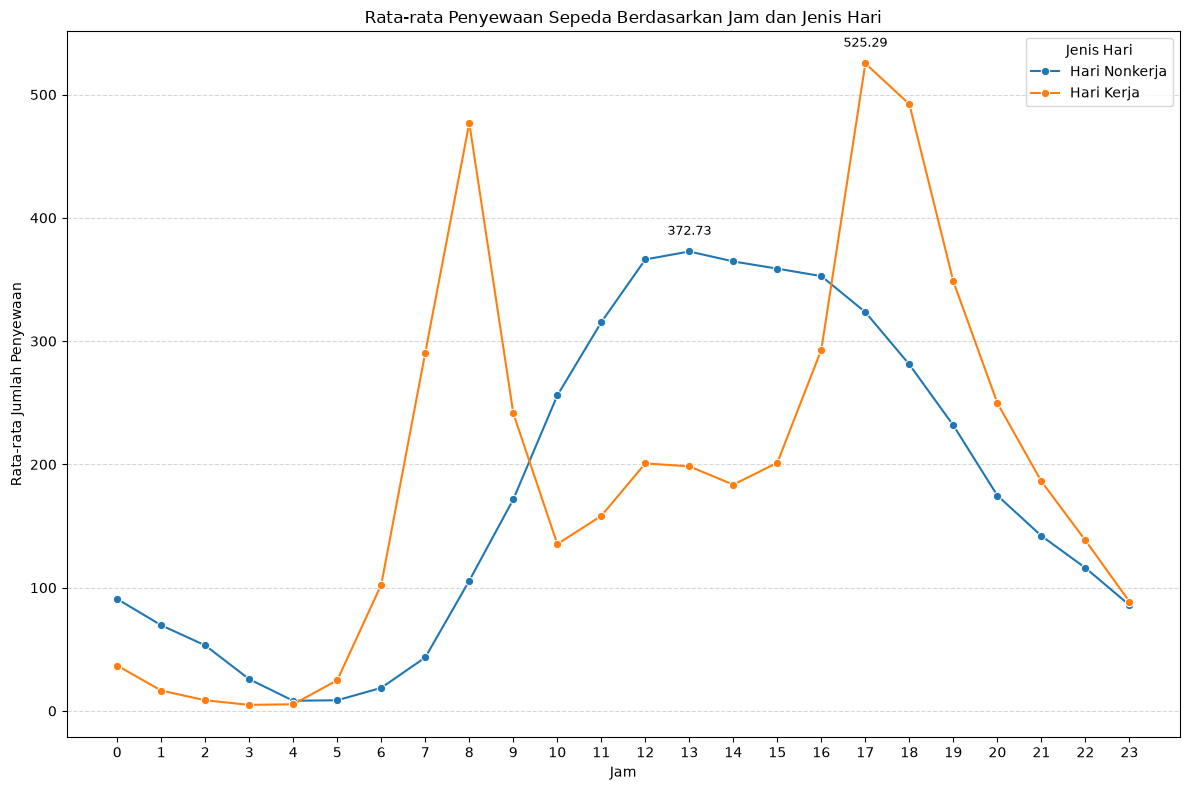

In [13]:
# Menghitung rata-rata penyewaan berdasarkan jam dan jenis hari
workingday_hour = (
    hour_df.groupby(["workingday", "hr"], observed=True)["cnt"]
    .mean()
    .reset_index()
)

# Memberikan label jenis hari
workingday_hour["jenis_hari"] = workingday_hour["workingday"].map({
    0: "Hari Nonkerja",
    1: "Hari Kerja"
})

# Mencari titik puncak pada masing-masing jenis hari
peak_by_day = workingday_hour.loc[
    workingday_hour.groupby("workingday", observed=True)["cnt"].idxmax()
]

# Membuat grafik
plt.figure(figsize=(12, 8))

ax = sns.lineplot(
    data=workingday_hour,
    x="hr",
    y="cnt",
    hue="jenis_hari",
    marker="o"
)

# Menambahkan anotasi pada titik puncak
for _, row in peak_by_day.iterrows():
    ax.annotate(
        f"{row['cnt']:.2f}",
        xy=(row["hr"], row["cnt"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam dan Jenis Hari")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(range(24))
plt.legend(title="Jenis Hari")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Pertanyaan 2:
Pertanyaan: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda pada empat kategori kondisi cuaca selama 2011–2012, dan bagaimana hasilnya dapat digunakan untuk menyesuaikan perencanaan operasional layanan?

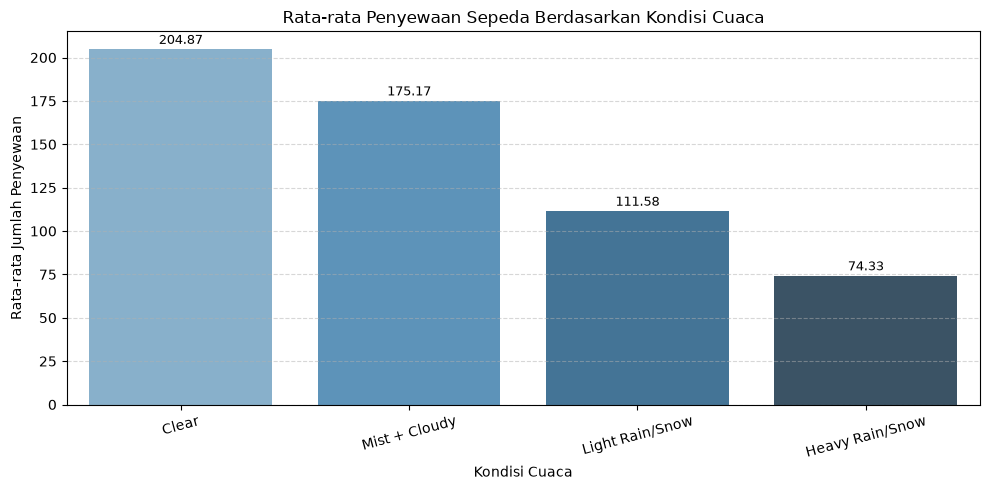

In [14]:
# Menghitung rata-rata penyewaan dan jumlah pengamatan berdasarkan cuaca
weather_avg = (
    hour_df.groupby("weathersit", observed=True)
    .agg(
        rata_rata_penyewaan=("cnt", "mean"),
        jumlah_pengamatan=("cnt", "size")
    )
    .reset_index()
)

# Memberikan label kondisi cuaca sesuai Readme dataset
weather_labels = {
    1: "Clear",
    2: "Mist + Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
}

weather_avg["kondisi_cuaca"] = weather_avg["weathersit"].map(weather_labels)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=weather_avg,
    x="kondisi_cuaca",
    y="rata_rata_penyewaan",
    hue="kondisi_cuaca",
    palette="Blues_d",
    dodge=False,
    legend=False
)

# Menambahkan angka rata-rata
for i, row in weather_avg.iterrows():
    ax.text(
        i,
        row["rata_rata_penyewaan"] + 3,
        f"{row['rata_rata_penyewaan']:.2f}",
        ha="center",
        fontsize=9
    )


plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
plt.xlabel("Kondisi Cuaca")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Insight pola penyewaan berdasarkan jam dan jenis hari**

Berdasarkan hasil visualisasi, terdapat perbedaan pola penyewaan sepeda antara hari kerja dan hari nonkerja. Pada hari kerja, rata-rata penyewaan tertinggi terjadi pada pukul 17.00, yaitu sebesar 525,29 penyewaan. Sementara itu, pada hari nonkerja, rata-rata penyewaan tertinggi terjadi pada pukul 13.00, yaitu sebesar 372,73 penyewaan.

Secara keseluruhan, rata-rata penyewaan sepeda tertinggi terjadi pada pukul 17.00, dengan rata-rata 461,45 penyewaan. Hal ini menunjukkan bahwa waktu dengan permintaan penyewaan tertinggi berbeda antara hari kerja dan hari nonkerja. Pada hari kerja, tingginya penyewaan menjelang sore dapat berkaitan dengan aktivitas pulang kerja, sedangkan pada hari nonkerja, tingginya penyewaan pada siang hari dapat berkaitan dengan aktivitas santai atau rekreasi.

- **Insight pola penyewaan berdasarkan kondisi cuaca**

Berdasarkan hasil analisis, kondisi cuaca Clear memiliki rata-rata penyewaan sepeda tertinggi, yaitu 204,87 penyewaan. Sebaliknya, kondisi cuaca Heavy Rain/Snow memiliki rata-rata penyewaan terendah, yaitu 74,33 penyewaan.

Hasil ini menunjukkan bahwa rata-rata penyewaan sepeda cenderung lebih tinggi ketika cuaca cerah dan lebih rendah ketika kondisi cuaca memburuk. Kondisi cuaca kemungkinan menjadi salah satu faktor yang berkaitan dengan keputusan pengguna untuk menyewa sepeda.

Namun, terdapat hal penting yang perlu diperhatikan pada kondisi Heavy Rain/Snow. Jumlah pengamatannya hanya 3 data, jauh lebih sedikit dibandingkan kondisi Clear sebanyak 11.413 data, Mist + Cloudy sebanyak 4.544 data, dan Light Rain/Snow sebanyak 1.419 data. Oleh karena itu, rata-rata pada kondisi Heavy Rain/Snow perlu ditafsirkan secara hati-hati karena jumlah datanya sangat terbatas dan belum tentu mewakili pola penyewaan secara umum.

## Analisis Lanjutan (Opsional)

**Tujuan analisis**

Analisis ini bertujuan mengetahui apakah rata-rata penyewaan sepeda pada jam-jam tertentu menunjukkan pola yang berbeda ketika kondisi cuaca berubah.

In [15]:
# Menghitung rata-rata penyewaan berdasarkan jam dan kondisi cuaca
weather_hour = (
    hour_df.groupby(["weathersit", "hr"], observed=True)["cnt"]
    .mean()
    .reset_index()
)

# Membuat tabel perbandingan
weather_hour_pivot = weather_hour.pivot(
    index="weathersit",
    columns="hr",
    values="cnt"
)

display(weather_hour_pivot.round(2))

hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weathersit,,,,,,,,,,,,,,,,,,,,,
1,59.16,34.40,22.82,12.00,6.41,20.41,79.17,218.74,361.36,226.39,...,269.46,275.23,335.75,500.43,458.44,336.10,244.87,186.83,142.60,93.98
2,47.23,35.54,25.49,12.45,6.72,20.14,74.61,224.73,391.28,226.85,...,208.65,227.81,299.64,422.90,390.42,282.02,204.54,151.82,116.82,85.17
3,28.12,17.13,14.84,6.94,4.68,13.88,55.98,131.07,213.78,128.98,...,122.08,138.06,167.19,275.99,271.04,179.53,126.21,98.53,70.35,49.37
4,NaN,23.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,36.00,NaN,164.00,NaN,NaN,NaN,NaN,NaN


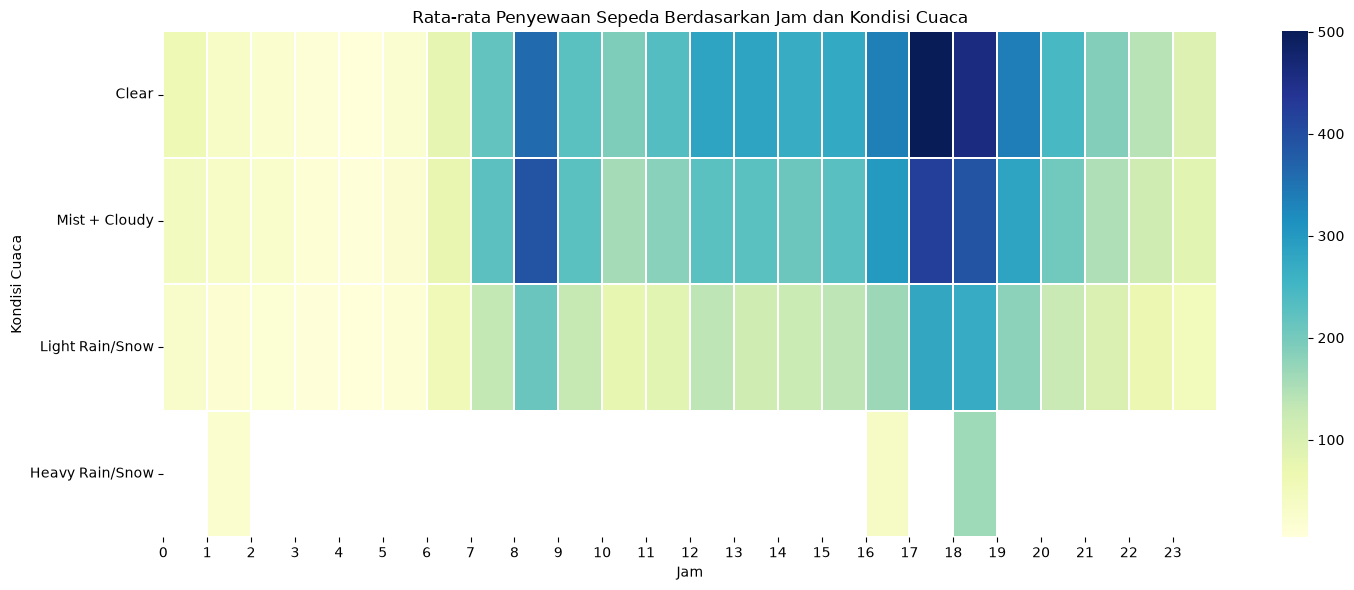

In [16]:
plt.figure(figsize=(15, 6))

sns.heatmap(
    weather_hour_pivot,
    cmap="YlGnBu",
    annot=False,
    linewidths=0.3
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam dan Kondisi Cuaca")
plt.xlabel("Jam")
plt.ylabel("Kondisi Cuaca")
plt.xticks(range(24), range(24))
plt.yticks(
    ticks=[0.5, 1.5, 2.5, 3.5],
    labels=["Clear", "Mist + Cloudy", "Light Rain/Snow", "Heavy Rain/Snow"],
    rotation=0
)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Berdasarkan heatmap, terlihat bahwa pola penyewaan sepeda pada setiap kondisi cuaca memiliki kecenderungan yang serupa, tetapi dengan tingkat penyewaan yang berbeda.
1. Cuaca Clear: Penyewaan sepeda menunjukkan tingkat yang relatif tinggi, terutama pada pukul 08.00 dan 17.00–18.00. Puncak penyewaan terlihat pada pukul 17.00.
2. Cuaca Mist + Cloudy: Pola penyewaan juga menunjukkan peningkatan pada pagi hari, khususnya pukul 08.00, serta sore hari pada pukul 17.00–18.00. Namun, tingkat penyewaannya cenderung lebih rendah dibandingkan cuaca cerah.
3. Cuaca Light Rain/Snow: Rata-rata penyewaan terlihat lebih rendah dibandingkan dua kondisi sebelumnya. Meskipun demikian, peningkatan masih terlihat pada pukul 08.00 dan 17.00–18.00.
4. Cuaca Heavy Rain/Snow: Data pada kondisi ini sangat terbatas sehingga sebagian besar jam tidak memiliki pengamatan. Oleh karena itu, pola penyewaan pada kondisi tersebut belum dapat dibandingkan secara menyeluruh dengan kondisi cuaca lainnya.

Secara keseluruhan, heatmap menunjukkan bahwa penyewaan sepeda cenderung meningkat pada jam-jam tertentu, terutama pagi dan sore hari. Kondisi cuaca yang lebih cerah juga terlihat berkaitan dengan rata-rata penyewaan yang lebih tinggi. Hal ini memperkuat temuan sebelumnya bahwa waktu dan kondisi cuaca merupakan dua aspek yang berkaitan dengan pola penyewaan sepeda.

**Kesimpulan analisis lanjutan**

Analisis lanjutan memberikan gambaran bahwa pola penyewaan berdasarkan jam relatif terlihat pada beberapa kondisi cuaca, terutama Clear, Mist + Cloudy, dan Light Rain/Snow. Peningkatan penyewaan pada pagi dan sore hari menunjukkan adanya pola waktu penggunaan sepeda yang cukup konsisten. Namun, kondisi cuaca tetap berkaitan dengan perbedaan tingkat penyewaan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pola penyewaan berdasarkan jam dan jenis hari

Berdasarkan hasil analisis, pola penyewaan sepeda berbeda antara hari kerja dan hari nonkerja. Pada hari kerja, rata-rata penyewaan tertinggi terjadi pada pukul 17.00 sebesar 525,29 penyewaan, sedangkan pada hari nonkerja terjadi pada pukul 13.00 sebesar 372,73 penyewaan. Secara keseluruhan, rata-rata penyewaan tertinggi terjadi pada pukul 17.00 sebesar 461,45 penyewaan. Hasil ini menunjukkan bahwa waktu penyewaan dengan permintaan tertinggi bergantung pada jenis hari.

- **Conclusion pertanyaan 2:** Pola penyewaan berdasarkan kondisi cuaca

Kondisi cuaca menunjukkan perbedaan rata-rata jumlah penyewaan sepeda. Cuaca Clear memiliki rata-rata penyewaan tertinggi sebesar 204,87, sedangkan Heavy Rain/Snow memiliki rata-rata terendah sebesar 74,33. Namun, kategori Heavy Rain/Snow hanya memiliki tiga pengamatan, sehingga hasilnya perlu ditafsirkan dengan hati-hati.

- **Conclusion Analisis lanjutan**

Hasil heatmap menunjukkan bahwa pola penyewaan cenderung meningkat pada jam-jam pagi dan sore, terutama pada kondisi cuaca Clear, Mist + Cloudy, dan Light Rain/Snow. Tingkat rata-rata penyewaan terlihat berbeda pada setiap kondisi cuaca. Dengan demikian, waktu dan kondisi cuaca dapat menjadi aspek yang dipertimbangkan dalam memahami pola permintaan penyewaan sepeda.

**Rekomendasi Action Item:**

Berdasarkan hasil analisis, berikut beberapa rekomendasi yang dapat dipertimbangkan oleh pengelola layanan penyewaan sepeda:

1. Mengoptimalkan ketersediaan sepeda pada jam sibuk. Pengelola dapat memastikan ketersediaan sepeda lebih banyak menjelang pukul 17.00 pada hari kerja karena periode tersebut memiliki rata-rata penyewaan tertinggi. Pada hari nonkerja, ketersediaan sepeda dapat lebih diperhatikan menjelang pukul 13.00.

2. Menyesuaikan operasional dengan kondisi cuaca. Pengelola dapat mempertimbangkan informasi prakiraan cuaca dalam merencanakan kebutuhan operasional dan distribusi sepeda. Ketika cuaca diperkirakan cerah, ketersediaan sepeda dapat dioptimalkan untuk mengantisipasi permintaan yang lebih tinggi.

3. Memperhatikan faktor keselamatan saat cuaca buruk. Ketika terjadi hujan atau kondisi cuaca yang kurang mendukung, pengelola dapat memberikan informasi keselamatan kepada pengguna serta memastikan fasilitas sepeda tetap dalam kondisi baik.

4. Melakukan pengamatan tambahan pada kondisi cuaca ekstrem. Karena data Heavy Rain/Snow hanya memiliki tiga pengamatan, diperlukan lebih banyak data sebelum mengambil keputusan operasional berdasarkan kategori cuaca tersebut.

**Penutup**

Secara keseluruhan, analisis ini menunjukkan bahwa pola penyewaan sepeda memiliki perbedaan berdasarkan waktu dan kondisi cuaca. Hasil analisis dapat dimanfaatkan sebagai bahan pertimbangan dalam mengatur ketersediaan sepeda, merencanakan operasional, dan meningkatkan kualitas layanan berdasarkan pola permintaan pengguna.

## Save Data yang telah dibersihkan

menyimpan data yg telah dibersihkan untuk pembuatan dashboard

In [17]:
hour_df.to_csv("dashboard/main_data.csv", index=False)